# Clase 04 — Del llanto a las predicciones: ¿qué aprende un clasificador?

**ACUS220 — Acústica Computacional con Python · Universidad Austral de Chile**  
**Fecha:** jueves 22 de octubre de 2026

## Pregunta de trabajo

> **¿Cómo podemos evaluar un clasificador de audio cuando algunas categorías tienen muchas más grabaciones que otras?**

En la [Clase 03](../03_exploracion_audio/clase03.ipynb) escuchamos señales del corpus **Donate-a-Cry**, analizamos formas de onda, STFT y representaciones Mel y log-Mel. Terminamos con una pregunta: *¿qué características acústicas podríamos entregar a un computador para que intente reconocer las etiquetas del corpus?*

En esta clase daremos el siguiente paso. Comenzaremos **sin aprendizaje de máquina**: un sistema trivial que siempre responde `hungry` nos ayudará a descubrir por qué un porcentaje alto de aciertos puede ser engañoso. Luego crearemos una tabla de características acústicas y realizaremos tres experimentos controlados.

**Precaución científica:** las etiquetas `hungry`, `discomfort`, `tired`, `belly_pain` y `burping` son **categorías proporcionadas por el corpus**. No constituyen por sí solas diagnósticos, estados fisiológicos verificados ni causas deducibles directamente de un sonido.

⚠️ **Clase 04 en construcción — 22 de octubre de 2026**

Este material se publica como avance docente. La revisión pedagógica y la comparación de los experimentos A, B y C están en desarrollo. Los resultados experimentales son preliminares.

## Nuestro recorrido

```text
Clase 03                                   Clase 04
escuchar → observar → representar     →    preguntar → etiquetar → medir desbalance
                                        →   definir una observación → extraer características
                                        →   separar entrenamiento/prueba → aprender
                                        →   predecir → evaluar por clase → comparar estrategias
```

**Al finalizar deberíamos poder:**

1. describir el desbalance entre categorías y calcular las métricas de un clasificador trivial;
2. diferenciar **grabación**, **etiqueta**, **característica**, **ejemplo de entrenamiento** y **predicción**;
3. reconocer por qué mezclar grabaciones relacionadas o aumentar datos antes de separar conjuntos causa *fuga de información* (*data leakage*);
4. representar cada grabación mediante características acústicas interpretables;
5. comparar **A: modelo sin balanceo**, **B: ponderación de clases** y **C: aumentación moderada con ruido gaussiano**, manteniendo el mismo conjunto de prueba;
6. expresar conclusiones prudentes basadas en métricas por clase, no únicamente en `accuracy`.

> **Dinámica sugerida:** detenerse al terminar cada actividad, discutir y recién entonces ejecutar la siguiente.

## 0. Preparación: reutilizamos los datos de la Clase 03

Trabajaremos con el **mismo corpus local**, sin volver a descargarlo y sin modificar sus archivos. El notebook busca `data_sources/` en el proyecto y en sus carpetas superiores, como hicimos en la Clase 03.

**Bibliotecas:** `numpy`, `pandas`, `matplotlib`, `librosa`, `scikit-learn` y `IPython` (la importación de scikit-learn aparece más adelante). Selecciona en VS Code el kernel **Python (acus220_2026)**.

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from IPython.display import display

SEMILLA = 220
np.random.seed(SEMILLA)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("librosa:", librosa.__version__)

NumPy: 2.5.3
pandas: 3.0.6
librosa: 1.0.0


In [19]:
def encontrar_corpus():
    ruta_relativa = Path(
        "data_sources/donateacry-corpus/"
        "donateacry_corpus_cleaned_and_updated_data"
    )
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        candidata = carpeta / ruta_relativa
        if candidata.is_dir():
            return candidata.resolve()
    raise FileNotFoundError(
        "No se encontró Donate-a-Cry. Abre este notebook dentro del proyecto "
        "20260810_acus220/Book-ACUS220 y verifica la carpeta data_sources/."
    )

DATA_ROOT = encontrar_corpus()
archivos = sorted(DATA_ROOT.rglob("*.wav"))
if not archivos:
    raise RuntimeError(f"No se encontraron grabaciones WAV en {DATA_ROOT}")

corpus = pd.DataFrame({
    "ruta": [p.relative_to(DATA_ROOT).as_posix() for p in archivos],
    "etiqueta": [p.parent.name for p in archivos],
})
assert corpus["ruta"].is_unique, "Se detectaron rutas repetidas."

print(f"Corpus: {DATA_ROOT}")
print(f"Grabaciones encontradas: {len(corpus)}")
display(corpus.head())

Corpus: /Users/vpoblete/Documents/20230208_vpoblete/20260810_acus220/data_sources/donateacry-corpus/donateacry_corpus_cleaned_and_updated_data
Grabaciones encontradas: 457


,ruta,etiqueta
0,belly_pain/549a46d8-9c84-430e-ade8-97eae2bef78...,belly_pain
1,belly_pain/643D64AD-B711-469A-AF69-55C0D5D3E30...,belly_pain
2,belly_pain/643D64AD-B711-469A-AF69-55C0D5D3E30...,belly_pain
3,belly_pain/643D64AD-B711-469A-AF69-55C0D5D3E30...,belly_pain
4,belly_pain/643D64AD-B711-469A-AF69-55C0D5D3E30...,belly_pain


---

## Actividad 1 — ¿Puede ser «bueno» un clasificador que no escucha?

### 1.1. Primero, observemos el desequilibrio

La **unidad de observación** de esta primera actividad será **una grabación WAV**: cada fila de nuestra tabla representa un archivo y trae una etiqueta del corpus.

Antes de ejecutar, conversen: ¿cuál es la clase más frecuente? ¿Cuál es la menos frecuente? ¿Qué ocurriría si siempre respondiéramos con la más frecuente?

In [20]:
conteos = (corpus["etiqueta"].value_counts()
           .rename_axis("etiqueta")
           .reset_index(name="grabaciones"))
conteos["porcentaje"] = (100 * conteos["grabaciones"] / len(corpus)).round(1)
display(conteos)

referencia = {
    "hungry": 382, "tired": 24, "burping": 8,
    "belly_pain": 16, "discomfort": 27,
}
observado = corpus["etiqueta"].value_counts().to_dict()
if observado == referencia:
    print("Auditoría: la distribución coincide con las 457 grabaciones de la Clase 03.")
else:
    print("Atención: la distribución difiere de la referencia de la Clase 03.")
    print("Trabajaremos con los conteos reales de esta carpeta; revisa la procedencia.")

,etiqueta,grabaciones,porcentaje
0,hungry,382,83.6
1,discomfort,27,5.9
2,tired,24,5.3
3,belly_pain,16,3.5
4,burping,8,1.8


Auditoría: la distribución coincide con las 457 grabaciones de la Clase 03.


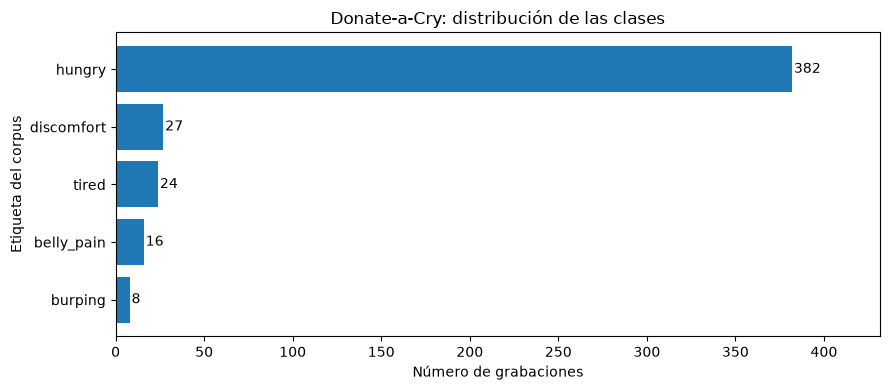

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = conteos.sort_values("grabaciones")
ax.barh(orden["etiqueta"], orden["grabaciones"])
ax.set_xlabel("Número de grabaciones")
ax.set_ylabel("Etiqueta del corpus")
ax.set_title("Donate-a-Cry: distribución de las clases")
for i, n in enumerate(orden["grabaciones"]):
    ax.text(n + 1, i, str(n), va="center")
ax.set_xlim(0, max(orden["grabaciones"]) * 1.13)
plt.tight_layout()
plt.show()

### 1.2. Inventemos un clasificador sin audio y sin entrenamiento

Nuestro primer «clasificador» aplica una sola regla:

> Para toda grabación, independientemente del sonido, predecir `hungry`.

Este sistema **no reconoce patrones**, **no extrae características** y **no aprende**. Aun así, podemos evaluar sus predicciones.

La *exactitud global* (*accuracy*) es la fracción de ejemplos cuya predicción coincide con la etiqueta:

$$
\operatorname{accuracy}=\frac{\text{predicciones correctas}}{\text{número total de ejemplos}}.
$$

**Antes de ejecutar:** usando únicamente los conteos, estimen qué `accuracy` obtendrá.

In [22]:
y_real = corpus["etiqueta"].to_numpy()
y_trivial = np.full(len(corpus), "hungry", dtype=object)

correctas = int(np.sum(y_trivial == y_real))
accuracy_trivial = correctas / len(y_real)

print("Clasificador trivial: siempre predice 'hungry'")
print(f"Predicciones correctas: {correctas} de {len(y_real)}")
print(f"Accuracy global: {100 * accuracy_trivial:.1f} %")

Clasificador trivial: siempre predice 'hungry'
Predicciones correctas: 382 de 457
Accuracy global: 83.6 %


### 1.3. Contemos los aciertos **por clase**

Hay dos preguntas diferentes:

- **Precision de una clase:** entre todas las veces que el sistema *predijo* esa clase, ¿cuántas acertó?
- **Recall de una clase:** entre todas las grabaciones que *realmente tenían* esa etiqueta, ¿cuántas identificó?

Una medida que combina ambas es el **F1-score**:

$$
F_1 = \frac{2\,\mathrm{precision}\,\mathrm{recall}}
{\mathrm{precision}+\mathrm{recall}}.
$$

Si un denominador es cero, en este ejercicio asignaremos cero a esa medida. **Todavía no necesitamos scikit-learn:** calcularemos las cantidades directamente con NumPy.

In [23]:
filas = []
for clase in sorted(corpus["etiqueta"].unique()):
    vp = int(np.sum((y_real == clase) & (y_trivial == clase)))
    fp = int(np.sum((y_real != clase) & (y_trivial == clase)))
    fn = int(np.sum((y_real == clase) & (y_trivial != clase)))
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    recall = vp / (vp + fn) if (vp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    filas.append({
        "clase": clase, "VP": vp, "FP": fp, "FN": fn,
        "precision": precision, "recall": recall, "F1": f1,
    })

metricas_trivial = pd.DataFrame(filas)
display(metricas_trivial.round(3))

balanced_accuracy_manual = metricas_trivial["recall"].mean()
f1_macro_manual = metricas_trivial["F1"].mean()
print(f"Accuracy global:    {accuracy_trivial:.3f}")
print(f"Balanced accuracy:  {balanced_accuracy_manual:.3f}")
print(f"F1 macro:           {f1_macro_manual:.3f}")

,clase,VP,FP,FN,precision,recall,F1
0,belly_pain,0,0,16,0.000,0.0,0.000
1,burping,0,0,8,0.000,0.0,0.000
2,discomfort,0,0,27,0.000,0.0,0.000
3,hungry,382,75,0,0.836,1.0,0.911
4,tired,0,0,24,0.000,0.0,0.000


Accuracy global:    0.836
Balanced accuracy:  0.200
F1 macro:           0.182


### 1.4. ¿Qué significan los promedios?

- **Accuracy global:** da el mismo peso a cada **grabación**; por ello la clase grande influye mucho.
- **Balanced accuracy:** promedia el *recall* de las clases; cada **clase** cuenta por igual.
- **F1 macro:** promedia el F1 de cada clase; también asigna igual importancia a las clases, pero combina *precision* y *recall*.

En un conjunto con cinco clases, un sistema que predice exclusivamente una clase presente obtiene *recall* 1 para esa clase y 0 para las cuatro restantes: su balanced accuracy es $1/5 = 0.20$.

Veamos ahora una **matriz de confusión**: las filas indicarán etiquetas reales y las columnas, predicciones. Un modelo con buenos resultados en todas las clases tendería a acumular aciertos en la diagonal.

In [24]:
clases = sorted(corpus["etiqueta"].unique())
matriz_trivial = pd.crosstab(
    pd.Categorical(y_real, categories=clases),
    pd.Categorical(y_trivial, categories=clases),
    rownames=["Etiqueta real"], colnames=["Predicción"],
    dropna=False,
)
print("Matriz de confusión del clasificador trivial:")
display(matriz_trivial)

Matriz de confusión del clasificador trivial:


Predicción,belly_pain,burping,discomfort,hungry,tired
Etiqueta real,,,,,
belly_pain,0,0,0,16,0
burping,0,0,0,8,0
discomfort,0,0,0,27,0
hungry,0,0,0,382,0
tired,0,0,0,24,0


### 1.5. Discusión antes de continuar

**Respondan en parejas:**

1. ¿Por qué la `accuracy` de este sistema puede parecer alta?
2. ¿Qué clases no logra identificar **nunca**?
3. ¿En qué sentido la balanced accuracy refleja un problema que la accuracy oculta?
4. ¿Este sistema aprendió algo sobre frecuencia fundamental, energía o espectrogramas?
5. ¿Sería responsable presentar su resultado como un sistema que reconoce las *causas* del llanto?

**Conclusión de la Actividad 1:** un porcentaje global elevado **no demuestra** que podamos distinguir entre categorías. Desde ahora, todo modelo debe compararse con este baseline y evaluarse **por clase**.

> **Pausa pedagógica:** hasta aquí no hemos importado ningún clasificador ni entrenado nada. La lección sobre desbalance está completa por sí misma.

---

## Actividad 2 — ¿Cómo representamos una grabación con números?

Un clasificador tabular necesita una matriz de características $X$ y un vector de etiquetas $y$.

- **Una fila de $X$:** una grabación.
- **Una columna de $X$:** una medida obtenida de esa señal.
- **Una posición de $y$:** la etiqueta asociada a esa grabación.

Para conectar con la Clase 03 resumiremos mediciones a lo largo del tiempo: energía RMS, tasa de cruces por cero, centroide espectral, ancho de banda espectral y **13 MFCC**, usando medias y desviaciones estándar.

**Limitación intencional:** estos promedios eliminan gran parte de las trayectorias temporales del llanto. Son un punto de partida interpretable, no una representación óptima ni una prueba de que las etiquetas correspondan a causas reales.

### 2.1. Definamos una receta reproducible

Cada archivo se convertirá a mono y a **8 kHz** para obtener características comparables. Recordemos de la Clase 03 que, para $f_s=8000$ Hz, la frecuencia de Nyquist es **4000 Hz**. Es una elección computacional que restringe la información de altas frecuencias.

Los parámetros que fijamos son `n_fft=1024`, `hop_length=256` y `n_mfcc=13`.

In [25]:
FS_OBJETIVO = 8000
N_FFT = 1024
HOP_LENGTH = 256
N_MFCC = 13

nombres_features = [
    "rms_media", "rms_std", "zcr_media", "zcr_std",
    "centroide_media_hz", "centroide_std_hz",
    "ancho_banda_media_hz", "ancho_banda_std_hz",
]
for i in range(1, N_MFCC + 1):
    nombres_features.extend([f"mfcc{i:02d}_media", f"mfcc{i:02d}_std"])


def leer_grabacion(ruta_relativa):
    y_audio, sr = librosa.load(DATA_ROOT / ruta_relativa, sr=FS_OBJETIVO, mono=True)
    if not len(y_audio):
        raise ValueError(f"Grabación vacía: {ruta_relativa}")
    return y_audio, sr


def extraer_caracteristicas(y_audio, sr):
    rms = librosa.feature.rms(y=y_audio, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    zcr = librosa.feature.zero_crossing_rate(
        y=y_audio, frame_length=N_FFT, hop_length=HOP_LENGTH
    )[0]
    centroide = librosa.feature.spectral_centroid(
        y=y_audio, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH
    )[0]
    ancho = librosa.feature.spectral_bandwidth(
        y=y_audio, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH
    )[0]
    mfcc = librosa.feature.mfcc(
        y=y_audio, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH
    )
    resultado = []
    for vector in [rms, zcr, centroide, ancho]:
        resultado.extend([float(np.mean(vector)), float(np.std(vector))])
    for fila_mfcc in mfcc:
        resultado.extend([float(np.mean(fila_mfcc)), float(np.std(fila_mfcc))])
    valores = np.asarray(resultado, dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError("Se encontraron características no finitas; revisar el archivo.")
    return valores

assert len(nombres_features) == 8 + 2 * N_MFCC
print(f"Características por grabación: {len(nombres_features)}")

Características por grabación: 34


### 2.2. Una grabación antes que todo el corpus

Inspeccionemos las dimensiones. La duración de la grabación se muestra como **información descriptiva**, pero no se incluirá en el modelo para evitar que la duración de los archivos se convierta sin querer en un atajo asociado al modo en que fueron recolectados.

In [26]:
ruta_ejemplo = corpus.iloc[0]["ruta"]
audio_ejemplo, sr_ejemplo = leer_grabacion(ruta_ejemplo)
vector_ejemplo = extraer_caracteristicas(audio_ejemplo, sr_ejemplo)

print("Ejemplo:", ruta_ejemplo)
print(f"Muestras de audio: {len(audio_ejemplo)}")
print(f"Duración: {len(audio_ejemplo) / sr_ejemplo:.2f} s")
print(f"Forma de X para una grabación: ({len(vector_ejemplo)},)")
display(pd.DataFrame({"caracteristica": nombres_features, "valor": vector_ejemplo}).head(12))

Ejemplo: belly_pain/549a46d8-9c84-430e-ade8-97eae2bef787-1430130772174-1.7-m-48-bp.wav
Muestras de audio: 54880
Duración: 6.86 s
Forma de X para una grabación: (34,)


,caracteristica,valor
0,rms_media,0.019665
1,rms_std,0.023198
2,zcr_media,0.248992
3,zcr_std,0.131357
4,centroide_media_hz,1314.343070
5,centroide_std_hz,511.921507
6,ancho_banda_media_hz,770.372664
7,ancho_banda_std_hz,254.712619
8,mfcc01_media,-486.545319
9,mfcc01_std,164.097885


### 2.3. Construyamos $X$ e $y$

Ahora aplicaremos exactamente la misma receta a las grabaciones originales. Según la duración de los archivos, esta celda puede requerir más tiempo que las anteriores. No se modifica el audio ni se guarda una copia del corpus.

In [27]:
filas_X = []
for i, ruta in enumerate(corpus["ruta"], start=1):
    audio, sr = leer_grabacion(ruta)
    filas_X.append(extraer_caracteristicas(audio, sr))
    if i % 100 == 0 or i == len(corpus):
        print(f"Procesadas {i}/{len(corpus)} grabaciones")

X = pd.DataFrame(filas_X, columns=nombres_features, index=corpus.index)
y = corpus["etiqueta"].copy()

assert X.shape == (len(corpus), len(nombres_features))
assert y.shape == (len(corpus),)
assert np.isfinite(X.to_numpy()).all()
print("Forma de X:", X.shape, "| Forma de y:", y.shape)
display(X.head().iloc[:, :10].round(3))

Procesadas 100/457 grabaciones
Procesadas 200/457 grabaciones
Procesadas 300/457 grabaciones
Procesadas 400/457 grabaciones
Procesadas 457/457 grabaciones
Forma de X: (457, 34) | Forma de y: (457,)


,rms_media,rms_std,zcr_media,zcr_std,centroide_media_hz,centroide_std_hz,ancho_banda_media_hz,ancho_banda_std_hz,mfcc01_media,mfcc01_std
0,0.020,0.023,0.249,0.131,1314.343,511.922,770.373,254.713,-486.545,164.098
1,0.006,0.007,0.208,0.073,1267.623,211.378,981.609,110.228,-459.901,66.595
2,0.013,0.016,0.216,0.059,1264.529,202.351,963.986,70.680,-382.619,88.945
3,0.021,0.019,0.237,0.069,1312.804,256.802,930.625,153.334,-332.583,69.147
4,0.042,0.035,0.209,0.064,1264.196,230.415,1005.965,90.065,-253.708,53.822


### 2.4. Verifica que entendiste la representación

- ¿Por qué una fila de la matriz **no** equivale a un instante de tiempo?
- ¿Cuáles columnas tienen una interpretación física relativamente directa?
- ¿Qué se pierde al reemplazar una secuencia MFCC por su media y desviación estándar?
- ¿Cuáles características podrían ser sensibles a nivel de grabación, micrófono o ruido de fondo?

Las características calculadas describen la señal; **no verifican** por sí mismas la etiqueta.

---

## Actividad 3 — Separar antes de aprender: entrenamiento y prueba

Nuestro objetivo no es memorizar las grabaciones ya observadas: es evaluar el desempeño con grabaciones **no usadas para entrenar**.

```text
Datos originales
     ├── entrenamiento → calcular escalamiento y ajustar modelos
     └── prueba        → solo transformar con el escalamiento aprendido y evaluar
```

### Una advertencia importante sobre el origen de los datos

Una grabación es una observación, pero **varias grabaciones podrían proceder de un mismo bebé, sesión o fuente**. Si esto sucede, un reparto aleatorio de archivos puede dar resultados artificialmente optimistas.

**No suponemos** que el identificador incluido en el nombre WAV sea un identificador verificado del bebé. Si dispones de metadatos confiables puedes cargar un CSV con columnas `ruta` y `grupo` (por ejemplo, identificador real de participante o sesión). Así evitamos que un mismo grupo aparezca en entrenamiento y prueba.

En ausencia de esos metadatos, realizaremos un reparto estratificado por etiqueta y lo declararemos como **limitación**. Una separación estratificada **no garantiza independencia por bebé**.

In [28]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# Opcional: ruta a un CSV auditado con columnas "ruta" y "grupo".
# Debe cubrir exactamente las rutas relativas listadas en la tabla corpus.
# No rellenar con supuestos extraídos del nombre del archivo.
CSV_GRUPOS = None

indices = np.arange(len(corpus))
if CSV_GRUPOS is None:
    idx_entrena, idx_prueba = train_test_split(
        indices, test_size=0.25, random_state=SEMILLA,
        stratify=y.to_numpy(),
    )
    print("Separación estratificada por etiqueta (sin grupos confiables).")
    print("LIMITACIÓN: no se puede descartar dependencia entre grabaciones.")
else:
    tabla_grupos = pd.read_csv(CSV_GRUPOS)
    if not {"ruta", "grupo"}.issubset(tabla_grupos.columns):
        raise ValueError("El CSV de grupos debe contener 'ruta' y 'grupo'.")
    if tabla_grupos["ruta"].duplicated().any():
        raise ValueError("Hay rutas duplicadas en el CSV de grupos.")
    mapeo = tabla_grupos.set_index("ruta")["grupo"]
    grupos = corpus["ruta"].map(mapeo)
    if grupos.isna().any():
        raise ValueError("Faltan grupos para algunas grabaciones.")

    # Elegimos entre particiones reproducibles que conserven las cinco clases
    # en ambos conjuntos. No hay estratificación perfecta garantizada por grupos.
    opciones = GroupShuffleSplit(n_splits=200, test_size=0.25, random_state=SEMILLA)
    proporcion_global = y.value_counts(normalize=True).reindex(clases, fill_value=0)
    candidatos = []
    for entrena, prueba in opciones.split(X, y, groups=grupos):
        if set(y.iloc[entrena]) != set(clases) or set(y.iloc[prueba]) != set(clases):
            continue
        p_test = y.iloc[prueba].value_counts(normalize=True).reindex(clases, fill_value=0)
        error = float((p_test - proporcion_global).abs().sum())
        candidatos.append((error, entrena, prueba))
    if not candidatos:
        raise ValueError(
            "No se encontró una partición por grupos que contenga todas las "
            "clases en entrenamiento y prueba. Revisar los metadatos y el diseño."
        )
    _, idx_entrena, idx_prueba = min(candidatos, key=lambda z: z[0])
    assert set(grupos.iloc[idx_entrena]).isdisjoint(set(grupos.iloc[idx_prueba]))
    print("Separación por grupos verificados: sin grupos compartidos.")

idx_entrena = np.sort(idx_entrena)
idx_prueba = np.sort(idx_prueba)
assert set(idx_entrena).isdisjoint(set(idx_prueba))
assert len(idx_entrena) + len(idx_prueba) == len(corpus)

X_entrena, X_prueba = X.iloc[idx_entrena], X.iloc[idx_prueba]
y_entrena, y_prueba = y.iloc[idx_entrena], y.iloc[idx_prueba]

resumen_particion = pd.DataFrame({
    "entrenamiento": y_entrena.value_counts().reindex(clases, fill_value=0),
    "prueba": y_prueba.value_counts().reindex(clases, fill_value=0),
})
print("Grabaciones de entrenamiento:", len(idx_entrena))
print("Grabaciones de prueba:", len(idx_prueba))
display(resumen_particion)

Separación estratificada por etiqueta (sin grupos confiables).
LIMITACIÓN: no se puede descartar dependencia entre grabaciones.
Grabaciones de entrenamiento: 342
Grabaciones de prueba: 115


,entrenamiento,prueba
etiqueta,,
belly_pain,12,4
burping,6,2
discomfort,20,7
hungry,286,96
tired,18,6


### 3.1. Un baseline justo para comparar los modelos

En la Actividad 1 calculamos un resultado ilustrativo con las **457 etiquetas**. Para comparar A, B y C en igualdad de condiciones, volveremos a evaluar el clasificador trivial **solo en el conjunto de prueba**. Las métricas pueden variar ligeramente respecto del corpus completo.

Aquí introducimos `scikit-learn` para calcular y mostrar métricas con una misma función para todos los sistemas.

In [29]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)


def evaluar(nombre, etiquetas_reales, predicciones, mostrar=True):
    resumen = {
        "sistema": nombre,
        "accuracy": accuracy_score(etiquetas_reales, predicciones),
        "balanced_accuracy": balanced_accuracy_score(etiquetas_reales, predicciones),
        "F1_macro": f1_score(
            etiquetas_reales, predicciones,
            labels=clases, average="macro", zero_division=0,
        ),
    }
    if mostrar:
        print(f"\n{nombre}")
        display(pd.DataFrame([resumen]).round(3))
        print("Informe por clase:")
        print(classification_report(
            etiquetas_reales, predicciones, labels=clases, zero_division=0,
        ))
    return resumen

pred_trivial_prueba = np.full(len(y_prueba), "hungry", dtype=object)
resultado_trivial = evaluar("Trivial: siempre hungry", y_prueba, pred_trivial_prueba)


Trivial: siempre hungry


,sistema,accuracy,balanced_accuracy,F1_macro
0,Trivial: siempre hungry,0.835,0.2,0.182


Informe por clase:
              precision    recall  f1-score   support

  belly_pain       0.00      0.00      0.00         4
     burping       0.00      0.00      0.00         2
  discomfort       0.00      0.00      0.00         7
      hungry       0.83      1.00      0.91        96
       tired       0.00      0.00      0.00         6

    accuracy                           0.83       115
   macro avg       0.17      0.20      0.18       115
weighted avg       0.70      0.83      0.76       115



---

## Actividad 4 — Experimento A: entrenar sin balancear

Nuestro primer modelo que sí aprende será una **regresión logística multiclase**. No es un modelo de redes neuronales. Aprende relaciones entre características acústicas y etiquetas a partir de ejemplos.

La secuencia de procesamiento será:

```text
características de entrenamiento → escalamiento → entrenamiento del modelo
características de prueba        → mismo escalamiento → predicciones
```

Usaremos un `Pipeline` para que el escalamiento se ajuste **únicamente con entrenamiento**, y no con todo el conjunto.

**Decisión experimental:** mantener el algoritmo y los demás parámetros iguales al comparar A, B y C; modificaremos solo la estrategia frente al desbalance.

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


def construir_modelo(peso_clases=None):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight=peso_clases,
            max_iter=2000,
            random_state=SEMILLA,
        ),
    )
    

modelo_A = construir_modelo()
modelo_A.fit(X_entrena, y_entrena)
pred_A = modelo_A.predict(X_prueba)
resultado_A = evaluar("A · Sin balanceo", y_prueba, pred_A)


A · Sin balanceo


,sistema,accuracy,balanced_accuracy,F1_macro
0,A · Sin balanceo,0.826,0.277,0.318


Informe por clase:
              precision    recall  f1-score   support

  belly_pain       1.00      0.25      0.40         4
     burping       0.00      0.00      0.00         2
  discomfort       0.00      0.00      0.00         7
      hungry       0.85      0.97      0.90        96
       tired       1.00      0.17      0.29         6

    accuracy                           0.83       115
   macro avg       0.57      0.28      0.32       115
weighted avg       0.79      0.83      0.78       115



### ¿Qué debemos observar?

No basta con preguntar si A supera al clasificador trivial en `accuracy`. Nos interesa observar especialmente:

- ¿qué clases tienen `recall` bajo o nulo?;
- ¿aumenta la balanced accuracy frente al baseline?;
- ¿son las diferencias creíbles con tan pocas grabaciones en algunas clases?

No ajustaremos los parámetros del modelo mirando estos resultados de prueba: hacerlo transformaría la prueba en un conjunto de selección de modelos.

---

## Actividad 5 — Experimento B: dar más peso a clases poco frecuentes

Una estrategia es modificar **cuánto importa el error de cada clase durante el entrenamiento**. `class_weight="balanced"` asigna automáticamente pesos inversamente relacionados con la frecuencia de cada etiqueta **en el conjunto de entrenamiento**.

Los audios son los mismos; **no** duplicamos grabaciones ni modificamos el audio. Se modifica la función de aprendizaje.

In [31]:
modelo_B = construir_modelo(peso_clases="balanced")
modelo_B.fit(X_entrena, y_entrena)
pred_B = modelo_B.predict(X_prueba)
resultado_B = evaluar("B · Ponderación de clases", y_prueba, pred_B)


B · Ponderación de clases


,sistema,accuracy,balanced_accuracy,F1_macro
0,B · Ponderación de clases,0.487,0.376,0.253


Informe por clase:
              precision    recall  f1-score   support

  belly_pain       0.19      0.75      0.30         4
     burping       0.00      0.00      0.00         2
  discomfort       0.10      0.29      0.15         7
      hungry       0.84      0.51      0.64        96
       tired       0.12      0.33      0.18         6

    accuracy                           0.49       115
   macro avg       0.25      0.38      0.25       115
weighted avg       0.72      0.49      0.56       115



### Pregunta de interpretación

Si B mejora el `recall` de una clase minoritaria pero reduce la `accuracy`, ¿significa necesariamente que sea un modelo peor? Antes de responder, identifiquen **qué errores cambiaron** y qué criterio consideran importante para esta tarea.

---

## Actividad 6 — Experimento C: aumentación *solo* en entrenamiento

La tercera estrategia modifica la **señal de audio**: construiremos **dos versiones adicionales**, con ruido gaussiano suave, de cada grabación de clases minoritarias que pertenezca al conjunto de entrenamiento.

En la literatura de clasificación de llanto infantil se ha recurrido a la aumentación de datos para estudiar el desbalance. Aquí no intentaremos reproducir exactamente un procedimiento publicado: haremos un experimento **pequeño, explícito y reproducible**.

Para una señal $x[n]$, la versión aumentada será:

$$
x_{\mathrm{aug}}[n] = x[n] + \sigma\,\varepsilon[n],
\qquad \varepsilon[n]\sim\mathcal{N}(0,1).
$$

Ajustaremos $\sigma$ para obtener aproximadamente **25 dB de relación señal/ruido** en amplitud RMS. Al fijar `SEMILLA`, el ruido será reproducible.

**Regla fundamental:** nunca aumentaremos audios de prueba ni introduciremos versiones del mismo audio en ambos conjuntos. Tampoco aplicaremos aumentación a las grabaciones de `hungry`.

**Precaución:** el ruido gaussiano no crea nuevos bebés ni nueva información causal. Las versiones sintéticas están correlacionadas con sus grabaciones originales; por tanto, no constituyen observaciones independientes para la evaluación.

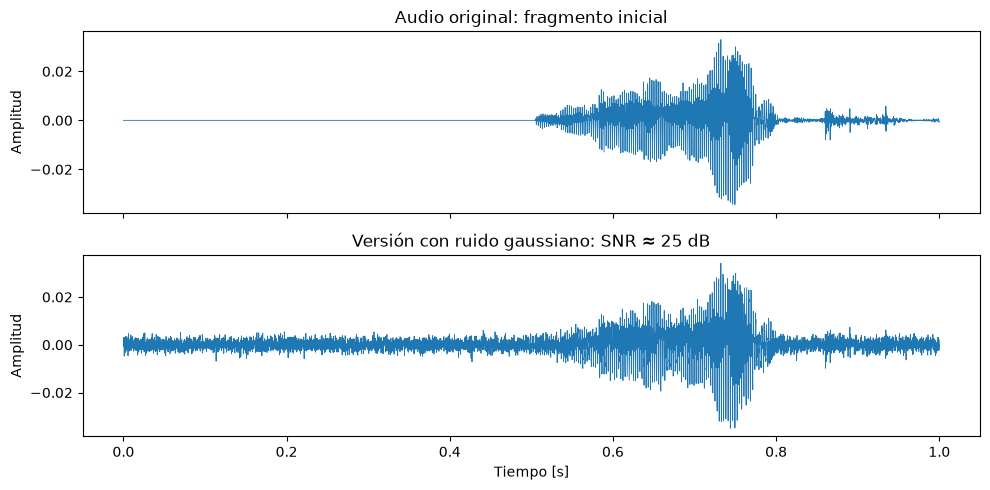

In [32]:
COPIAS_POR_GRABACION = 2
SNR_DB = 25.0
rng = np.random.default_rng(SEMILLA)


def agregar_ruido_gaussiano(audio, snr_db, generador):
    rms_audio = float(np.sqrt(np.mean(audio.astype(float) ** 2)))
    if rms_audio < 1e-10:
        return audio.copy()  # No inventar una señal a partir de silencio digital.
    ruido = generador.standard_normal(len(audio))
    ruido /= np.sqrt(np.mean(ruido ** 2)) + 1e-12
    rms_ruido_objetivo = rms_audio / (10 ** (snr_db / 20))
    return np.asarray(audio + rms_ruido_objetivo * ruido, dtype=np.float32)

# Demostración sobre un audio de entrenamiento minoritario (nunca de prueba).
minoritaria = corpus.iloc[idx_entrena]
minoritaria = minoritaria[minoritaria["etiqueta"] != "hungry"]
if minoritaria.empty:
    raise RuntimeError("No hay grabaciones minoritarias en entrenamiento.")
ruta_demo = minoritaria.iloc[0]["ruta"]
audio_demo, sr_demo = leer_grabacion(ruta_demo)
audio_demo_ruido = agregar_ruido_gaussiano(
    audio_demo, SNR_DB, np.random.default_rng(SEMILLA)
)

muestras_demo = min(len(audio_demo), sr_demo)
tiempos = np.arange(muestras_demo) / sr_demo
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(tiempos, audio_demo[:muestras_demo], lw=0.6)
ax[0].set_title("Audio original: fragmento inicial")
ax[1].plot(tiempos, audio_demo_ruido[:muestras_demo], lw=0.6)
ax[1].set_title(f"Versión con ruido gaussiano: SNR ≈ {SNR_DB:g} dB")
ax[1].set_xlabel("Tiempo [s]")
for eje in ax:
    eje.set_ylabel("Amplitud")
plt.tight_layout()
plt.show()

### 6.1. Generemos las nuevas características

Solo leemos las rutas indexadas como **entrenamiento**. Conservaremos las características originales y agregaremos filas correspondientes a sus versiones con ruido. El conjunto `X_prueba` permanece **idéntico** al de los experimentos A y B.

In [33]:
filas_aumentadas = []
etiquetas_aumentadas = []
for indice in idx_entrena:
    etiqueta = corpus.loc[indice, "etiqueta"]
    if etiqueta == "hungry":
        continue
    audio, sr = leer_grabacion(corpus.loc[indice, "ruta"])
    for _ in range(COPIAS_POR_GRABACION):
        audio_nuevo = agregar_ruido_gaussiano(audio, SNR_DB, rng)
        filas_aumentadas.append(extraer_caracteristicas(audio_nuevo, sr))
        etiquetas_aumentadas.append(etiqueta)

X_extra = pd.DataFrame(filas_aumentadas, columns=nombres_features)
y_extra = pd.Series(etiquetas_aumentadas, name="etiqueta")

# Cada fila añadida proviene exclusivamente de una grabación de entrenamiento.
X_entrena_C = pd.concat([X_entrena.reset_index(drop=True), X_extra], ignore_index=True)
y_entrena_C = pd.concat([y_entrena.reset_index(drop=True), y_extra], ignore_index=True)
assert len(X_entrena_C) == len(y_entrena_C)
assert len(X_prueba) == len(idx_prueba)  # La evaluación sigue siendo intocable.

comparacion_conteos = pd.DataFrame({
    "original_entrenamiento": y_entrena.value_counts().reindex(clases, fill_value=0),
    "entrenamiento_C": y_entrena_C.value_counts().reindex(clases, fill_value=0),
})
print(f"Nuevas filas sintéticas de entrenamiento: {len(y_extra)}")
print(f"Grabaciones originales en prueba: {len(X_prueba)} (sin cambios)")
display(comparacion_conteos)

Nuevas filas sintéticas de entrenamiento: 112
Grabaciones originales en prueba: 115 (sin cambios)


,original_entrenamiento,entrenamiento_C
etiqueta,,
belly_pain,12,36
burping,6,18
discomfort,20,60
hungry,286,286
tired,18,54


### 6.2. Entrenemos C con el mismo algoritmo que A

Para aislar el efecto de la aumentación, no pondremos ponderación de clases en C. El modelo C será el **mismo tipo de regresión logística**, pero recibirá las características originales **más** las versiones aumentadas de las clases minoritarias de entrenamiento.

In [34]:
modelo_C = construir_modelo()
modelo_C.fit(X_entrena_C, y_entrena_C)
pred_C = modelo_C.predict(X_prueba)
resultado_C = evaluar("C · Aumentación con ruido gaussiano", y_prueba, pred_C)


C · Aumentación con ruido gaussiano


,sistema,accuracy,balanced_accuracy,F1_macro
0,C · Aumentación con ruido gaussiano,0.8,0.271,0.294


Informe por clase:
              precision    recall  f1-score   support

  belly_pain       0.50      0.25      0.33         4
     burping       0.00      0.00      0.00         2
  discomfort       0.00      0.00      0.00         7
      hungry       0.84      0.94      0.89        96
       tired       0.50      0.17      0.25         6

    accuracy                           0.80       115
   macro avg       0.37      0.27      0.29       115
weighted avg       0.75      0.80      0.76       115



---

## Actividad 7 — Comparemos los cuatro sistemas con la misma prueba

Usaremos la **misma partición** y las **mismas métricas** para el baseline trivial y los tres experimentos. En la evaluación no contamos archivos aumentados: una grabación sintética no es un nuevo bebé ni un nuevo caso independiente.

,accuracy,balanced_accuracy,F1_macro
sistema,,,
Trivial: siempre hungry,0.835,0.200,0.182
A · Sin balanceo,0.826,0.277,0.318
B · Ponderación de clases,0.487,0.376,0.253
C · Aumentación con ruido gaussiano,0.800,0.271,0.294


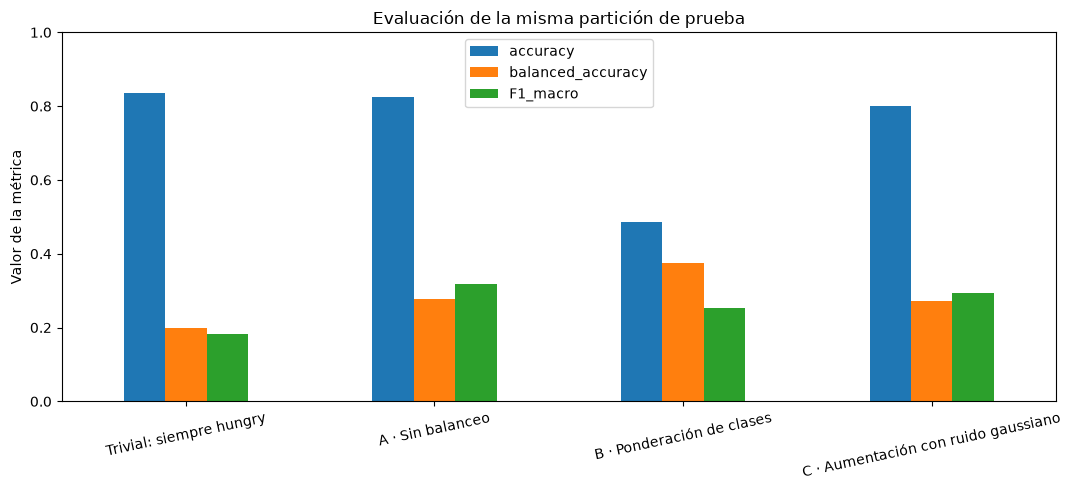

In [35]:
resultados = pd.DataFrame([
    resultado_trivial, resultado_A, resultado_B, resultado_C,
]).set_index("sistema")
display(resultados.round(3))

ax = resultados[["accuracy", "balanced_accuracy", "F1_macro"]].plot(
    kind="bar", figsize=(11, 5), rot=12, ylim=(0, 1)
)
ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("")
ax.set_title("Evaluación de la misma partición de prueba")
plt.tight_layout()
plt.show()

### 7.1. Matrices de confusión: ¿en qué clases falla cada sistema?

Cada matriz muestra la **cantidad** de casos, no un porcentaje. Para comparar clases de tamaños muy diferentes, los informes de `recall` complementan estas matrices.

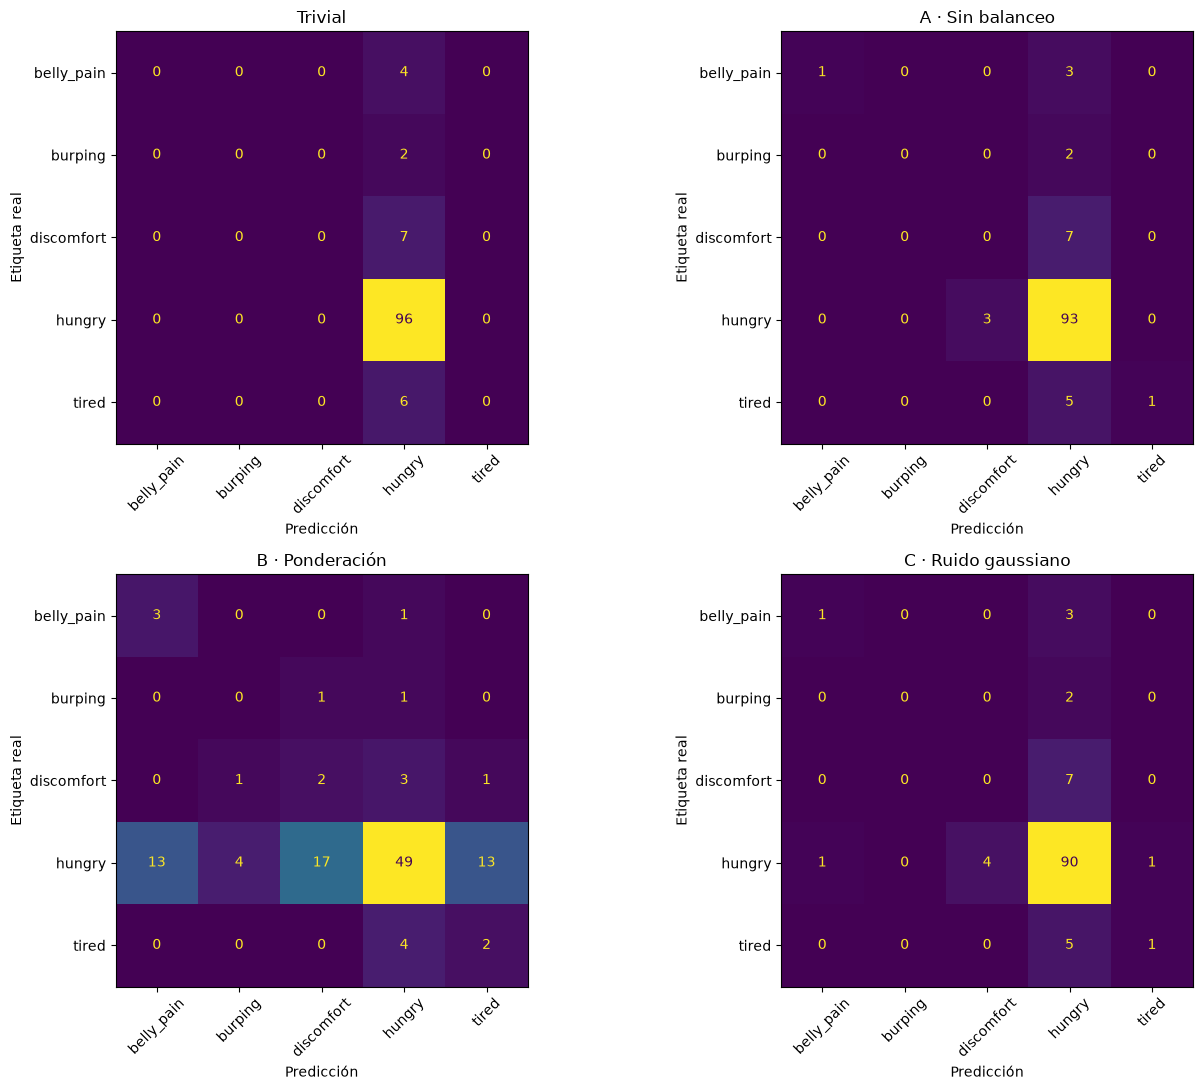

In [36]:
predicciones = [
    ("Trivial", pred_trivial_prueba),
    ("A · Sin balanceo", pred_A),
    ("B · Ponderación", pred_B),
    ("C · Ruido gaussiano", pred_C),
]
fig, ejes = plt.subplots(2, 2, figsize=(14, 11))
for eje, (nombre, pred) in zip(ejes.ravel(), predicciones):
    ConfusionMatrixDisplay.from_predictions(
        y_prueba, pred, labels=clases,
        ax=eje, colorbar=False, values_format="d",
        xticks_rotation=45,
    )
    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Etiqueta real")
plt.tight_layout()
plt.show()

### 7.2. Lectura crítica del experimento

Analicen los resultados **que efectivamente obtuvieron**, no los que esperaban obtener.

1. ¿Cuál de los modelos supera al trivial en balanced accuracy? ¿En F1 macro?
2. ¿Qué clases tienen cero aciertos o un *recall* pequeño? ¿Cuántos ejemplos reales había en esas clases?
3. ¿La ponderación mejoró el reconocimiento de clases poco frecuentes? ¿Con qué costo en otras clases?
4. ¿La aumentación con ruido produjo una mejora, un empate o un deterioro? **No presupongan** que aumentar datos siempre ayuda.
5. ¿Qué limita la generalización del experimento? Consideren etiquetas del corpus, tamaños de clase, dependencia entre grabaciones, representaciones acústicas y elección de un único reparto.
6. ¿Qué cambiaría si pudiéramos separar por **identificador verificado de bebé** o disponer de un conjunto externo?

**Sobre los resultados:** la prueba se conservó sin modificar para comparar experimentos didácticos predefinidos. No corresponde declarar «ganador» y ajustar hiperparámetros reiteradamente sobre esta misma prueba. Para desarrollar y seleccionar un modelo real necesitaríamos **validación independiente**, pruebas entre bebés y posiblemente evaluación externa.

## 8. Cierre — Aprender a evaluar es aprender a preguntar

Regresemos a la pregunta inicial:

> **¿Cómo podemos evaluar un clasificador cuando unas categorías tienen muchas más grabaciones que otras?**

Al comenzar, un clasificador que nunca escuchó el audio podía obtener una `accuracy` sorprendentemente alta. Ahora sabemos que una respuesta responsable requiere observar los errores **por clase**, definir con cuidado qué representa cada fila y evitar que la información de la prueba participe en el aprendizaje.

Nuestros tres experimentos no son una competición para afirmar que un algoritmo «detecta el hambre» a partir de la voz. Son una primera experiencia reproducible de **clasificación de audio y evaluación crítica**.

**Lo que nos llevamos para nuestros proyectos:**

- antes de entrenar, auditar los datos y construir un baseline;
- declarar la unidad de observación y el alcance de las etiquetas;
- separar entrenamiento y prueba antes de cualquier aumentación;
- prevenir la fuga de información si hay fuentes repetidas;
- comparar con las mismas particiones y métricas;
- no confundir desempeño numérico con validez científica o clínica.

**Extensión futura, no requerida hoy:** estudiar validación cruzada por grupos cuando existan metadatos confiables, incorporar descriptores temporales y contrastar evaluaciones entre fuentes o corpus.

---

### Nota de reproducibilidad y trazabilidad

Este notebook está pensado para el repositorio `vpobleteacustica/ACUS220-2026` como:

`contenidos/04_clasificacion_llanto/clase04.ipynb`

Reutiliza el corpus local de la Clase 03. No descarga, modifica ni exporta grabaciones. Mantiene fija la semilla aleatoria y separa la prueba antes de entrenar o aumentar audio.

**Para integrarlo al Jupyter Book**, se añadirá una entrada en `myst.yml` después de `contenidos/03_exploracion_audio/clase03.ipynb`, en una sección titulada «Clasificación de audio». **No se modifica la Clase 03.**